In [17]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('usa_housing.csv', encoding= "utf-8")
df.head()

,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
0,221958,1,1.9,4827,1979,2,1.45,82240,48.60,5
1,771155,2,2.0,1035,1987,2,1.75,74315,92.03,9
2,231932,1,3.0,2769,1982,1,1.46,79249,52.08,3
3,465838,3,3.3,2708,1907,3,1.62,80587,61.65,1
4,359178,4,3.4,1175,1994,2,0.74,20756,15.66,4


In [18]:
latest_year = df['YearBuilt'].max()
df = df[(df['YearBuilt'] > 2015) & (df['CrimeRate'] < 40)]
df.head()

,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
9,737147,3,2.6,4191,2017,0,1.65,66549,37.60,3
33,586232,4,1.3,3854,2021,2,1.39,30103,26.93,2
112,616588,2,1.2,3872,2016,0,0.17,61112,20.98,8
119,979858,5,3.8,4307,2020,0,0.38,41822,37.14,4
189,161087,5,2.4,964,2021,1,0.24,34022,12.80,3


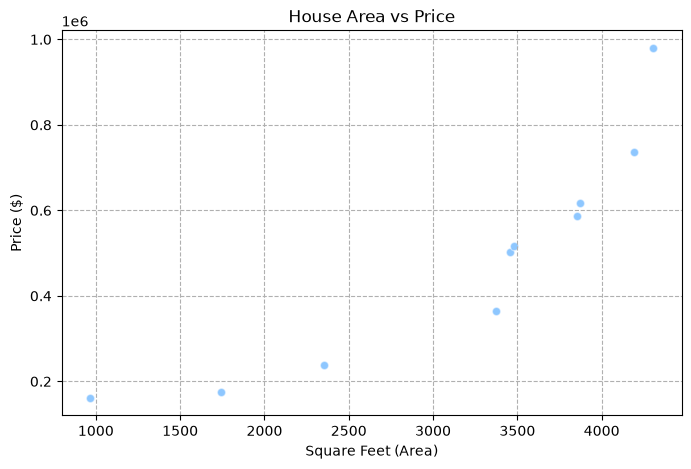

In [19]:
plt.figure(figsize=(8, 5))
plt.scatter(df['SquareFeet'], df['Price'], color = 'dodgerblue', alpha= 0.5, edgecolors='w')
plt.title("House Area vs Price")
plt.xlabel("Square Feet (Area)")
plt.ylabel("Price ($)")
plt.grid(True, linestyle = "--")
plt.show()

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error         # mse, mae

X = df[["SquareFeet"]]
y = df["Price"]


In [22]:
model = LinearRegression()
model.fit(X,y)

UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2879: illegal multibyte sequence

UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2879: illegal multibyte sequence

LinearRegression()

In [23]:
y_pred = model.predict(X)
y_pred

array([704505.64035344, 633657.39794181, 637441.57706172, 728892.57245951,
        26086.41702314, 189857.28004585, 318519.37012275, 532535.72257092,
       550195.22513049, 555240.79729037])

In [25]:
mae = mean_absolute_error(y,y_pred)
mse = mean_squared_error(y, y_pred)
print(f"컴퓨터가 찾은 기울기 w : {model.coef_}")
print(f"컴퓨터가 찾은 기본값 b : {model.intercept_:.2f}")
print(f"오차 제곱 평균 MSE : {mse:.2f}")
print(f"오차 절대갑 평균 MAE :  {mae:.2f}")

컴퓨터가 찾은 기울기 w : [210.23217333]
컴퓨터가 찾은 기본값 b : -176577.40
오차 제곱 평균 MSE : 12374713026.51
오차 절대갑 평균 MAE :  83721.47


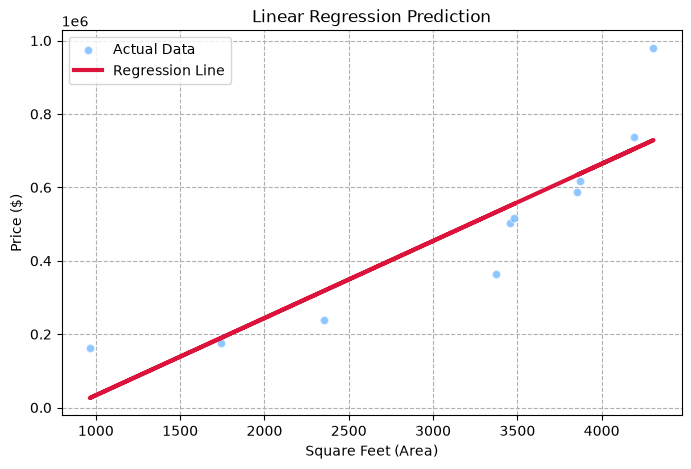

In [26]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='dodgerblue', alpha=0.5, edgecolor='w', label='Actual Data')
plt.plot(X, y_pred, color='crimson', linewidth=3, label='Regression Line')
plt.title('Linear Regression Prediction')
plt.xlabel('Square Feet (Area)')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True, linestyle='--')
plt.show()